# Assignment — Logistic Regression on `penguins.csv`

**Question:** given a penguin's measurements, is it male or female?

Target: `sex` &nbsp;·&nbsp; File: `penguins.csv`

Use only the numeric columns: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`,
`body_mass_g`.

**Keep this notebook.** Next class we will come back to the model you build here and
measure it properly.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


---
## 1. Look at the data

> **Flow:** Shape, columns, missing values.

Run `.info()`. Which columns have missing values, and how many?

In [2]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
None
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


How many male and how many female? Use `sns.countplot`.

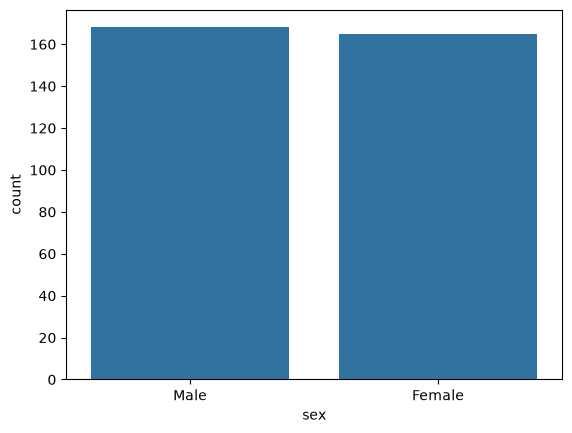

sex
Male      168
Female    165
Name: count, dtype: int64


In [3]:
sns.countplot(data=df, x='sex')
plt.show()

print(df['sex'].value_counts())

*Counts:* &nbsp;&nbsp; *Are the two classes roughly equal, or is one much bigger?*

Now compare the two groups on one measurement. Use `sns.barplot` with `x='sex'` and
`y='body_mass_g'`.

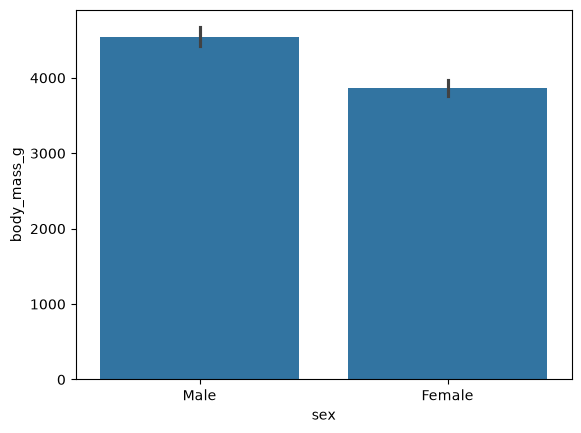

In [4]:
sns.barplot(data=df, x='sex', y='body_mass_g')
plt.show()

**Q.** Looking at that plot, does `body_mass_g` look useful for telling males and females
apart? One line.

Ans: Yes, body_mass_g looks useful because males have a noticeably higher average body mass than females.

---
## 2. Clean

> **Flow:** The target cannot be guessed. Rows missing it have to go.

`sex` is what we are trying to predict, so we cannot fill it in. Keep the four numeric
columns plus `sex`, then `dropna()`.

In [5]:
df_clean = df[
    ['bill_length_mm',
     'bill_depth_mm',
     'flipper_length_mm',
     'body_mass_g',
     'sex']
].dropna()

df_clean.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,Male
1,39.5,17.4,186.0,3800.0,Female
2,40.3,18.0,195.0,3250.0,Female
4,36.7,19.3,193.0,3450.0,Female
5,39.3,20.6,190.0,3650.0,Male


*How many rows are left?*

In [6]:
print(df_clean.shape[0])

333


The target is text — `Male` and `Female`. Map it to numbers:
`{'Female': 0, 'Male': 1}`.

In [7]:
df_clean['sex'] = df_clean['sex'].map({
    'Female': 0,
    'Male': 1
})

df_clean.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,1
1,39.5,17.4,186.0,3800.0,0
2,40.3,18.0,195.0,3250.0,0
4,36.7,19.3,193.0,3450.0,0
5,39.3,20.6,190.0,3650.0,1


---
## 3. Features and target

In [9]:
X = df_clean[
    ['bill_length_mm',
     'bill_depth_mm',
     'flipper_length_mm',
     'body_mass_g']
]

y = df_clean['sex']
print(X.shape)
print(y.shape)

(333, 4)
(333,)


---
## 4. Split

> **Flow:** `test_size=0.2`, `random_state=42`, `stratify=y`.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**Q.** Why do we use `stratify=y` here? One line.

Ans: stratify=y keeps the same proportion of male and female classes in both the training and test sets.

---
## 5. Train the model

> **Flow:** Two lines, same as always.

Train `LogisticRegression(max_iter=1000)` and predict on the test set.

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

**Q.** What does `max_iter=1000` do? One line.

Ans: max_iter=1000 allows the Logistic Regression optimization algorithm to perform up to 1000 iterations to converge.

The optimization algorithm is allowed to perform at most 1000 iterations while trying to find the best model parameters (weights and bias) so that its predictions are as accurate as possible.

---
## 6. Accuracy

In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8656716417910447
